# Exploratory data analysis

This notebook only draws pictures of the cleaned table.
It does not scale columns, split the rows, train a model, or change the uneven purchase split.

Every chart is saved at 150 dpi under `images/` and uses the values as they are stored.
A log scale, where it appears, is for the picture only.


### Load the cleaned file

`read_csv` turns the four code columns back into numbers. We cast them to text immediately.
`month_order` is the same Jan-to-Dec list used in the cleaning notebook. January and April are in that list and are absent from the file.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid")

if Path("data/processed/cleaned_shoppers.csv").exists():
    cleaned_path = Path("data/processed/cleaned_shoppers.csv")
    image_dir = Path("images")
else:
    cleaned_path = Path("../data/processed/cleaned_shoppers.csv")
    image_dir = Path("../images")

image_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(cleaned_path)
code_columns = ["OperatingSystems", "Browser", "Region", "TrafficType"]
for column in code_columns:
    df[column] = df[column].astype(str)

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]
present_months = [month for month in month_order if (df["Month"] == month).any()]
df["Month"] = pd.Categorical(df["Month"], categories=present_months, ordered=True)

assert len(df) == 12205
assert int(df.isna().sum().sum()) == 0
print("Rows:", len(df))
print("Missing cells:", int(df.isna().sum().sum()))
print("Months in calendar order:", present_months)
print("Absent from month_order:", [month for month in month_order if month not in present_months])


def save_and_show(fig, name):
    # name is the file stem after 02_.
    path = image_dir / f"02_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)
    plt.show()


Rows: 12205
Missing cells: 0
Months in calendar order: ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
Absent from month_order: ['Jan', 'Apr']


The file has **12,205** rows and **0** missing cells. The months present, in calendar order, are Feb through Dec except April. January and April are absent.


### 1. Did the visitor buy?

`Revenue` is 1 for a purchase and 0 otherwise. This chart only counts. It does not rebalance the classes.


Revenue
0    10297
1     1908
Revenue
0    84.37
1    15.63
Saved: ../images/02_revenue_counts.png


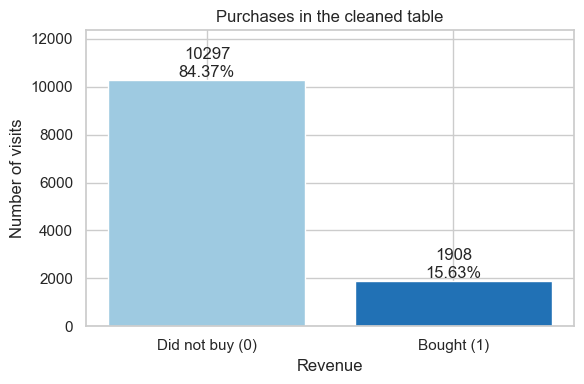

In [2]:
revenue_counts = df["Revenue"].value_counts().sort_index()
revenue_percent = 100 * revenue_counts / len(df)
print(revenue_counts.to_string())
print(revenue_percent.round(2).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Did not buy (0)", "Bought (1)"]
bars = ax.bar(labels, revenue_counts.values, color=["#9ecae1", "#2171b5"])
for bar, count, percent in zip(bars, revenue_counts.values, revenue_percent.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count)}\n{percent:.2f}%",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Number of visits")
ax.set_xlabel("Revenue")
ax.set_title("Purchases in the cleaned table")
ax.set_ylim(0, revenue_counts.max() * 1.2)
fig.tight_layout()
save_and_show(fig, "revenue_counts")


Of the **12,205** visits, **1,908** bought (**15.63%**) and **10,297** did not (**84.37%**). The classes stay uneven. This notebook does not change that.


### 2. Histograms of the numeric columns

The title of each panel is the percent of zeros. A log scale on the count axis is display only, and only where the raw counts would hide the tail. The table is not changed.


Percent of zeros:
  Administrative: 46.24%
  Administrative_Duration: 47.34%
  Informational: 78.44%
  Informational_Duration: 80.29%
  ProductRelated: 0.31%
  ProductRelated_Duration: 5.16%
  BounceRates: 45.21%
  ExitRates: 0.62%
  PageValues: 77.63%
  SpecialDay: 89.77%
  Weekend: 76.58%
  Revenue: 84.37%


Saved: ../images/02_histograms_numeric.png


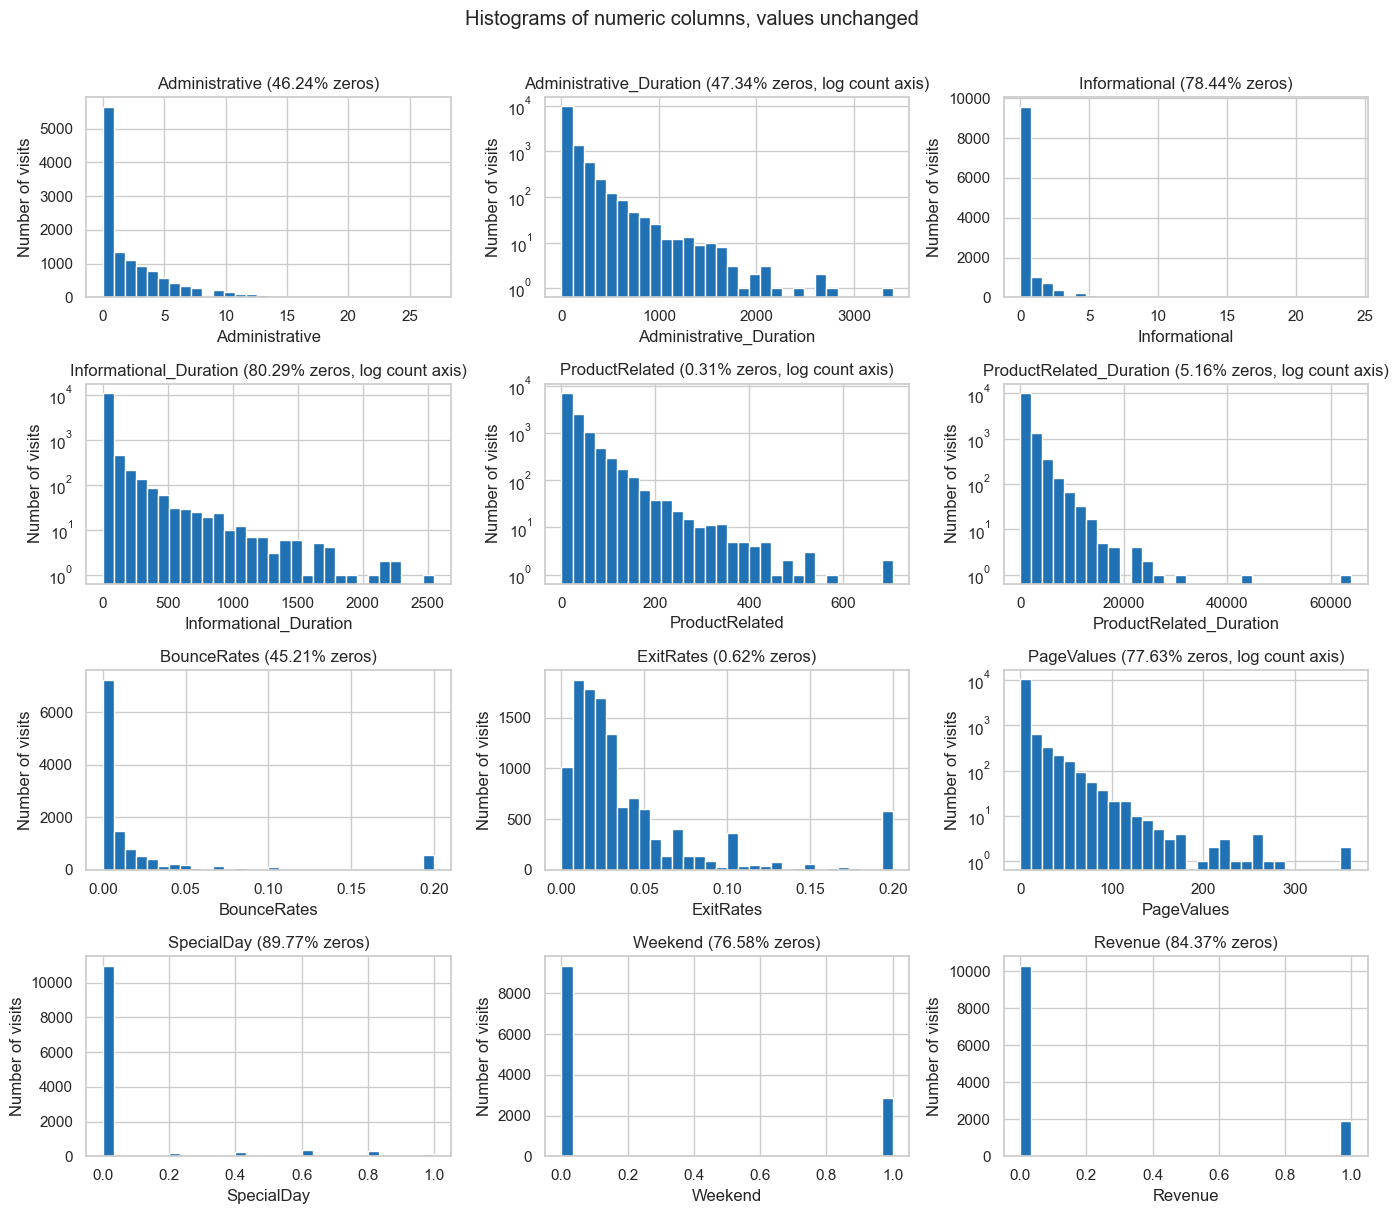

In [3]:
number_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Weekend",
    "Revenue",
]
# These columns run into the hundreds or thousands, so a log count axis shows the tail.
log_count_columns = {
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
}

print("Percent of zeros:")
for column in number_columns:
    percent_zero = 100 * (df[column] == 0).mean()
    print(f"  {column}: {percent_zero:.2f}%")

fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.ravel(), number_columns):
    percent_zero = 100 * (df[column] == 0).mean()
    ax.hist(df[column], bins=30, color="#2171b5")
    if column in log_count_columns:
        ax.set_yscale("log")
        scale_note = ", log count axis"
    else:
        scale_note = ""
    ax.set_title(f"{column} ({percent_zero:.2f}% zeros{scale_note})")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of visits")
fig.suptitle("Histograms of numeric columns, values unchanged", y=1.01)
fig.tight_layout()
save_and_show(fig, "histograms_numeric")


`SpecialDay` is 0 on **89.77%** of rows, `Informational_Duration` on **80.29%**, and `PageValues` on **77.63%**. `ProductRelated` is 0 on only **0.31%** of rows, and `ExitRates` on **0.62%**. `Revenue` is 0 on **84.37%** of rows, which is the same 10,297 non-buyers as the bar chart.


### 3. Boxplots

Each numeric column gets its own raw scale, so a long duration does not flatten the other boxes.
The second figure compares buyers and non-buyers on the columns with a real tail or a strong link to purchase. `log1p` on an axis is display only.


Saved: ../images/02_boxplots_numeric.png


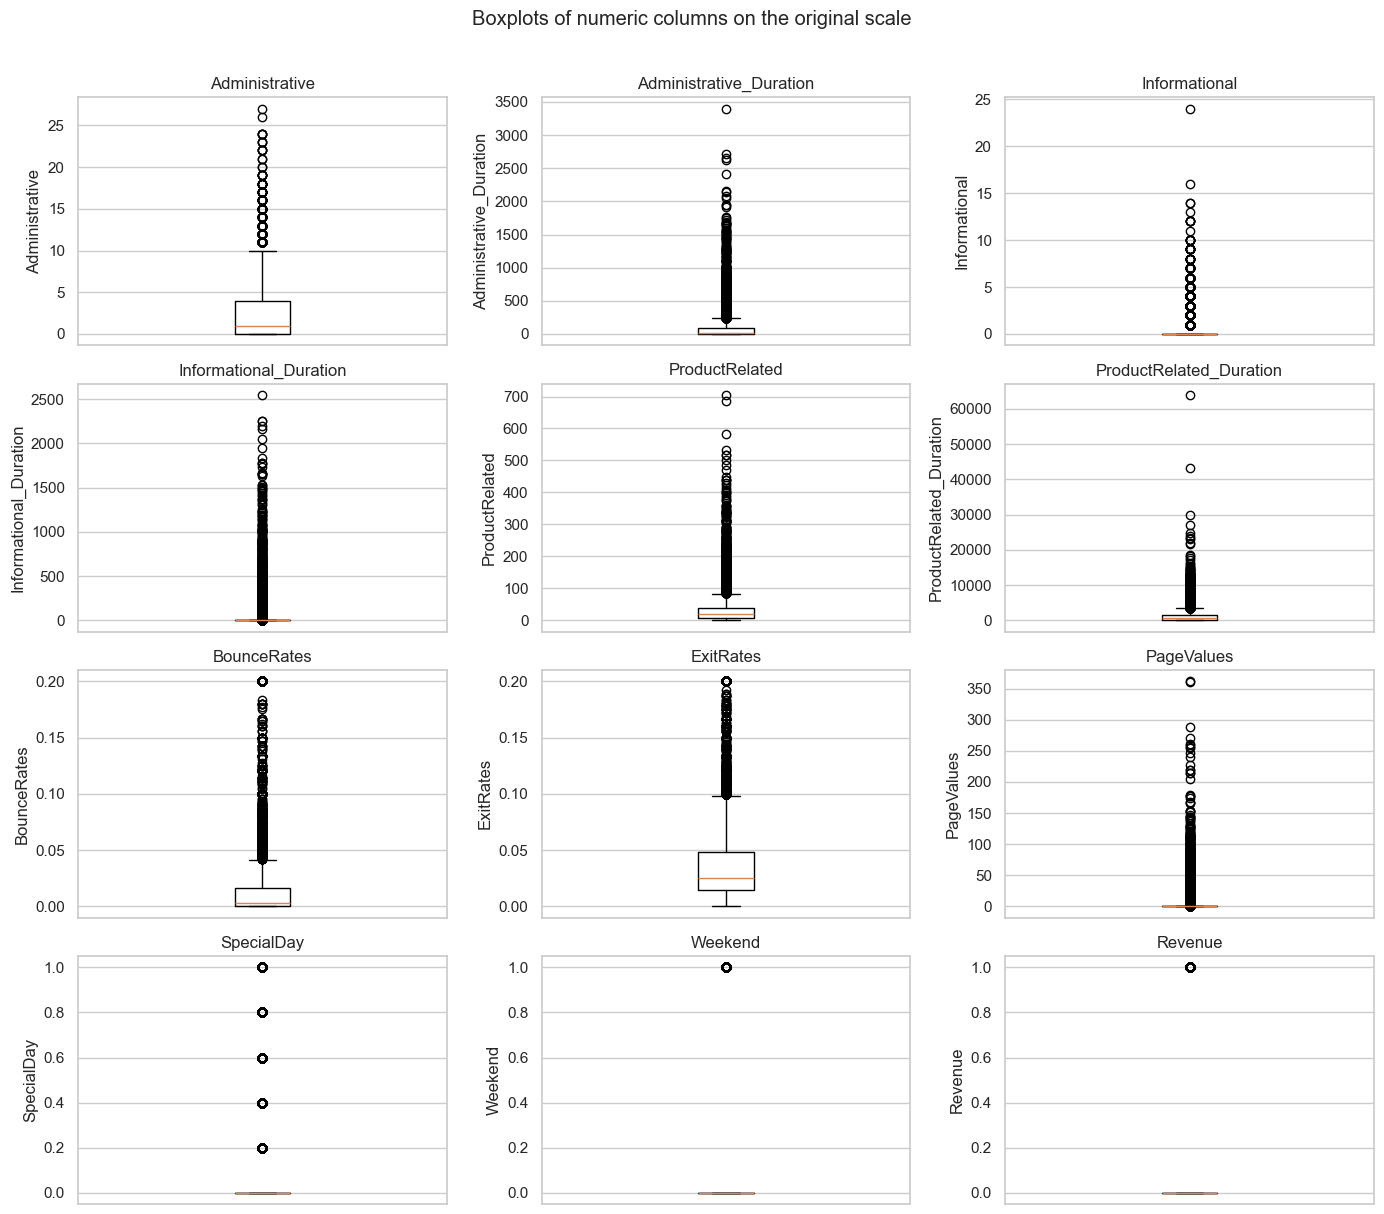

Median by Revenue. This print does not change the table:
  Administrative_Duration, Revenue 0: 0.00
  Administrative_Duration, Revenue 1: 52.37
  ProductRelated, Revenue 0: 16.00
  ProductRelated, Revenue 1: 29.00
  ProductRelated_Duration, Revenue 0: 526.00
  ProductRelated_Duration, Revenue 1: 1109.91
  PageValues, Revenue 0: 0.00
  PageValues, Revenue 1: 16.76
  BounceRates, Revenue 0: 0.00
  BounceRates, Revenue 1: 0.00
  ExitRates, Revenue 0: 0.03
  ExitRates, Revenue 1: 0.02


Saved: ../images/02_boxplots_by_revenue.png


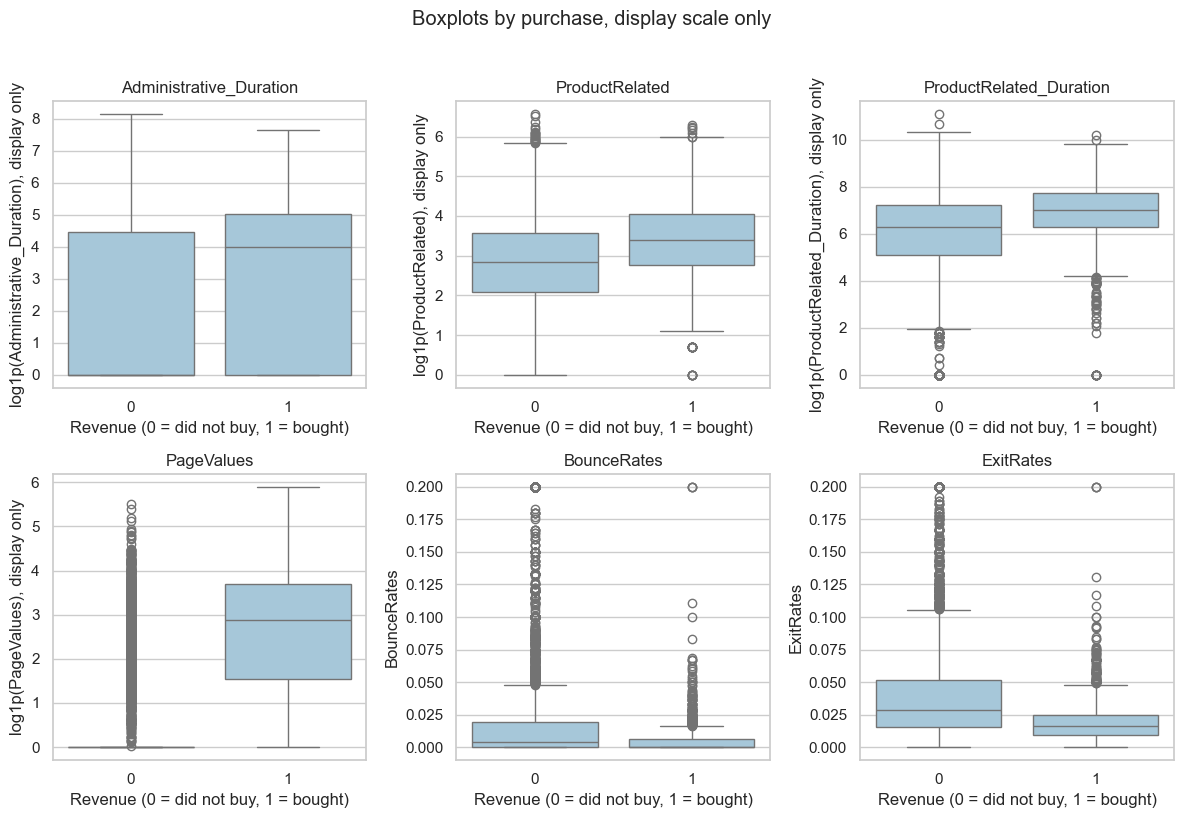

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.ravel(), number_columns):
    ax.boxplot(df[column], vert=True, showfliers=True)
    ax.set_title(column)
    ax.set_ylabel(column)
    ax.set_xticks([])
    ax.set_xlabel("")
fig.suptitle("Boxplots of numeric columns on the original scale", y=1.01)
fig.tight_layout()
save_and_show(fig, "boxplots_numeric")

key_columns = [
    "Administrative_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
    "BounceRates",
    "ExitRates",
]
print("Median by Revenue. This print does not change the table:")
for column in key_columns:
    for revenue_value in [0, 1]:
        median_value = df.loc[df["Revenue"] == revenue_value, column].median()
        print(f"  {column}, Revenue {revenue_value}: {median_value:.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, column in zip(axes.ravel(), key_columns):
    # A copy used only for the axis. df itself is not replaced.
    if df[column].max() > 1:
        shown = np.log1p(df[column])
        ylabel = f"log1p({column}), display only"
    else:
        shown = df[column]
        ylabel = column
    plot_frame = pd.DataFrame({"Revenue": df["Revenue"].astype(str), "shown": shown})
    sns.boxplot(data=plot_frame, x="Revenue", y="shown", ax=ax, color="#9ecae1")
    ax.set_title(column)
    ax.set_xlabel("Revenue (0 = did not buy, 1 = bought)")
    ax.set_ylabel(ylabel)
fig.suptitle("Boxplots by purchase, display scale only", y=1.02)
fig.tight_layout()
save_and_show(fig, "boxplots_by_revenue")


Buyers have a higher median `ProductRelated_Duration` (**1,109.91** versus **526.00**) and a higher median `PageValues` (**16.76** versus **0**). `BounceRates` has median **0** in both groups, because **45.21%** of all rows are already 0. Nothing was capped or deleted.


### 4. Correlation

The heatmap uses the numeric columns plus `Revenue`. A pair is listed when the absolute correlation is at least 0.7.
Correlation is a number from -1 to 1 that says how two columns move together. It is not proof that one causes the other.


Pairs with absolute correlation at least 0.7:
  ProductRelated and ProductRelated_Duration: 0.8603
  BounceRates and ExitRates: 0.9021
Pair count: 2


Saved: ../images/02_correlation_heatmap.png


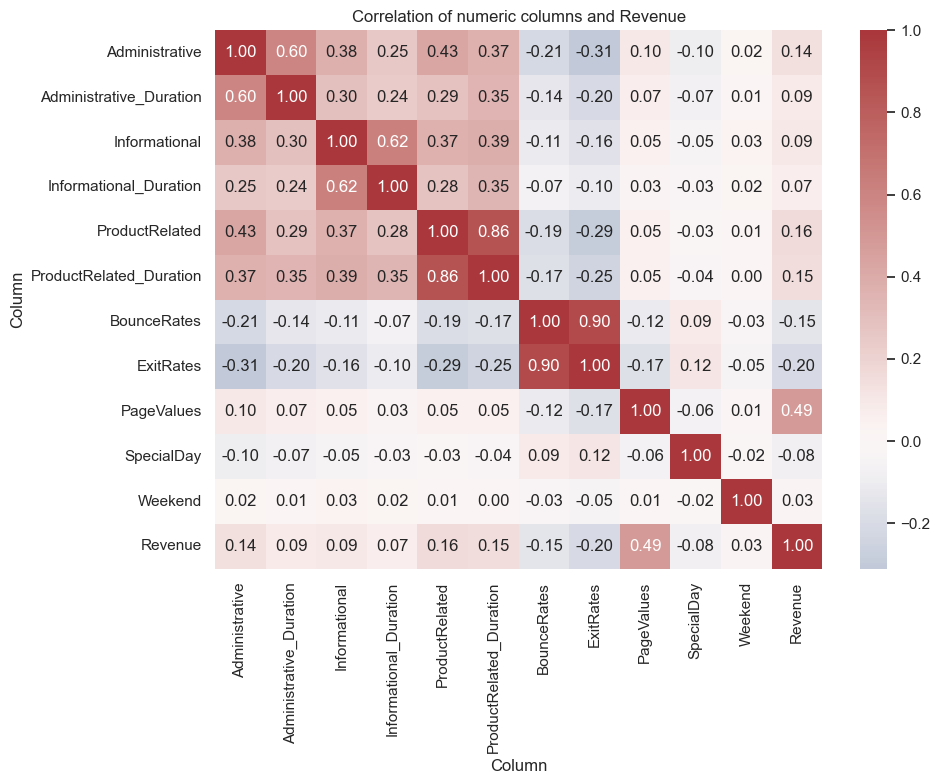

Correlation with Revenue:
ExitRates                 -0.2043
BounceRates               -0.1451
SpecialDay                -0.0836
Weekend                    0.0277
Informational_Duration     0.0694
Administrative_Duration    0.0918
Informational              0.0936
Administrative             0.1363
ProductRelated_Duration    0.1501
ProductRelated             0.1560
PageValues                 0.4919
Saved: ../images/02_correlation_with_revenue.png


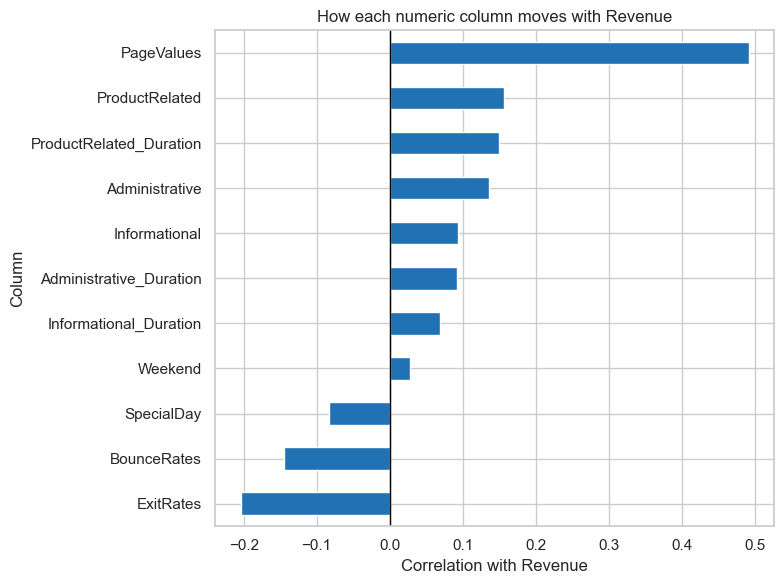

In [5]:
corr = df[number_columns].corr()
print("Pairs with absolute correlation at least 0.7:")
pair_count = 0
for left_index, left in enumerate(number_columns):
    for right in number_columns[left_index + 1 :]:
        value = corr.loc[left, right]
        if abs(value) >= 0.7:
            pair_count += 1
            print(f"  {left} and {right}: {value:.4f}")
print("Pair count:", pair_count)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of numeric columns and Revenue")
ax.set_xlabel("Column")
ax.set_ylabel("Column")
fig.tight_layout()
save_and_show(fig, "correlation_heatmap")

with_revenue = corr["Revenue"].drop("Revenue").sort_values()
print("Correlation with Revenue:")
print(with_revenue.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
with_revenue.plot(kind="barh", ax=ax, color="#2171b5")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Correlation with Revenue")
ax.set_ylabel("Column")
ax.set_title("How each numeric column moves with Revenue")
fig.tight_layout()
save_and_show(fig, "correlation_with_revenue")


Two pairs reach absolute correlation 0.7 or more: `BounceRates` with `ExitRates` (**r = 0.90**) and `ProductRelated` with `ProductRelated_Duration` (**r = 0.86**). `PageValues` has the strongest link to `Revenue` (**r = 0.49**). The strongest negative link is `ExitRates` (**r = -0.20**). `Weekend` is nearly flat (**r = 0.03**).


### 5. Buying rate by group

Each bar is the percent who bought. The label is the number of rows. A gray bar has fewer than 100 rows, so that percent is unreliable.
There is no year column, and January and April are missing, so month differences are seasonality inside this file, not a trend across time.


Month
       buyers     n   rate
Month                     
Feb         3   181   1.66
Mar       192  1860  10.32
May       365  3329  10.96
Jun        29   285  10.18
Jul        66   432  15.28
Aug        76   433  17.55
Sep        86   448  19.20
Oct       115   549  20.95
Nov       760  2982  25.49
Dec       216  1706  12.66
Groups under 100 rows: []


Saved: ../images/02_buying_rate_month.png


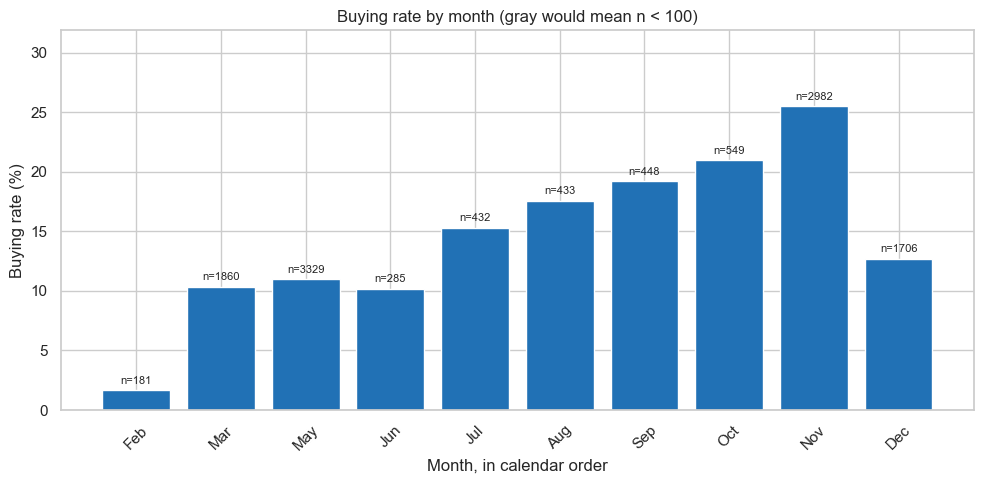

,buyers,n,rate
Month,,,
Feb,3,181,1.657459
Mar,192,1860,10.322581
May,365,3329,10.964254
Jun,29,285,10.175439
Jul,66,432,15.277778
Aug,76,433,17.551963
Sep,86,448,19.196429
Oct,115,549,20.947177
Nov,760,2982,25.486251


In [6]:
def buying_rate_bars(frame, column, filename, title, xlabel, order=None):
    grouped = frame.groupby(column, observed=False)["Revenue"].agg(buyers="sum", n="count")
    grouped["rate"] = 100 * grouped["buyers"] / grouped["n"]
    if order is not None:
        grouped = grouped.reindex(order).dropna(subset=["n"])
    print(column)
    print(grouped.round(2).to_string())
    small = grouped.index[grouped["n"] < 100].tolist()
    print("Groups under 100 rows:", small)

    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ["#bdbdbd" if n < 100 else "#2171b5" for n in grouped["n"]]
    bars = ax.bar([str(label) for label in grouped.index], grouped["rate"], color=colors)
    for bar, n_rows in zip(bars, grouped["n"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.4,
            f"n={int(n_rows)}",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_ylabel("Buying rate (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.set_ylim(0, max(grouped["rate"].max() * 1.25, 5))
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    save_and_show(fig, filename)
    return grouped


buying_rate_bars(
    df,
    "Month",
    "buying_rate_month",
    "Buying rate by month (gray would mean n < 100)",
    "Month, in calendar order",
    order=present_months,
)


November has the highest buying rate, **25.49%** (n = **2,982**). February has the lowest, **1.66%** (n = **181**). Every month in the file has at least 100 rows. January and April do not appear, and there is no year, so this is seasonality, not a trend.


VisitorType
                   buyers      n   rate
VisitorType                            
New_Visitor           422   1693  24.93
Returning_Visitor    1470  10431  14.09
Other                  16     81  19.75
Groups under 100 rows: ['Other']
Saved: ../images/02_buying_rate_visitor_type.png


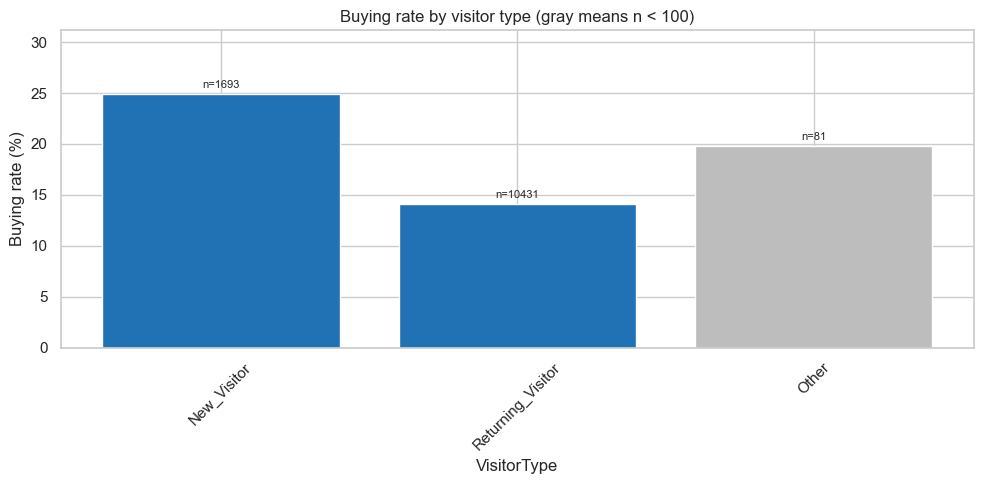

,buyers,n,rate
VisitorType,,,
New_Visitor,422,1693,24.926167
Returning_Visitor,1470,10431,14.092609
Other,16,81,19.753086


In [7]:
buying_rate_bars(
    df,
    "VisitorType",
    "buying_rate_visitor_type",
    "Buying rate by visitor type (gray means n < 100)",
    "VisitorType",
    order=["New_Visitor", "Returning_Visitor", "Other"],
)


New visitors buy at **24.93%** (n = **1,693**). Returning visitors buy at **14.09%** (n = **10,431**). `Other` is **19.75%**, but n = **81**, so that bar is gray and the percent is unreliable.


Weekend
         buyers     n   rate
Weekend                     
0          1409  9346  15.08
1           499  2859  17.45
Groups under 100 rows: []


Saved: ../images/02_buying_rate_weekend.png


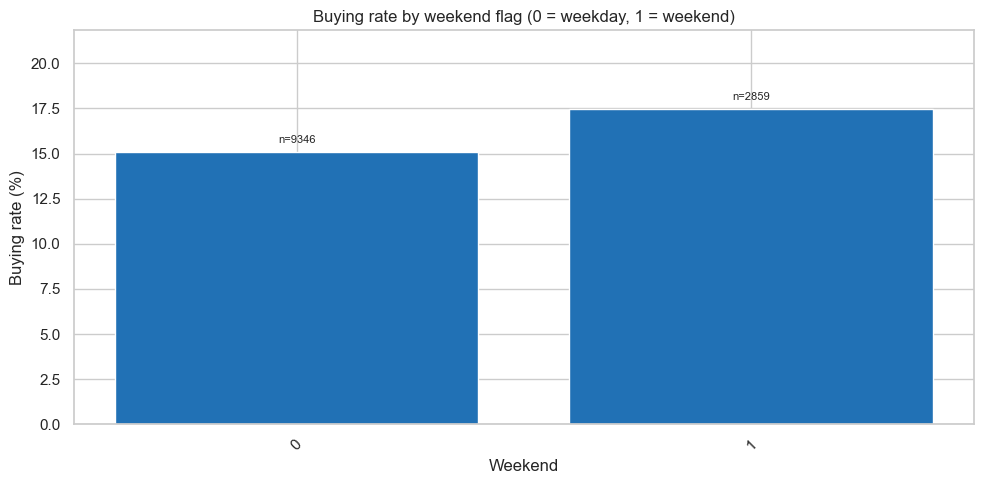

,buyers,n,rate
Weekend,,,
0,1409,9346,15.075968
1,499,2859,17.453655


In [8]:
buying_rate_bars(
    df,
    "Weekend",
    "buying_rate_weekend",
    "Buying rate by weekend flag (0 = weekday, 1 = weekend)",
    "Weekend",
    order=[0, 1],
)


Weekend visits buy at **17.45%** (n = **2,859**). Weekday visits buy at **15.08%** (n = **9,346**). Both groups are far above 100 rows, so the small gap is measured on large groups.


SpecialDay
            buyers      n   rate
SpecialDay                      
0.0           1831  10956  16.71
0.2             14    178   7.87
0.4             13    243   5.35
0.6             29    350   8.29
0.8             11    324   3.40
1.0             10    154   6.49
Groups under 100 rows: []


Saved: ../images/02_buying_rate_special_day.png


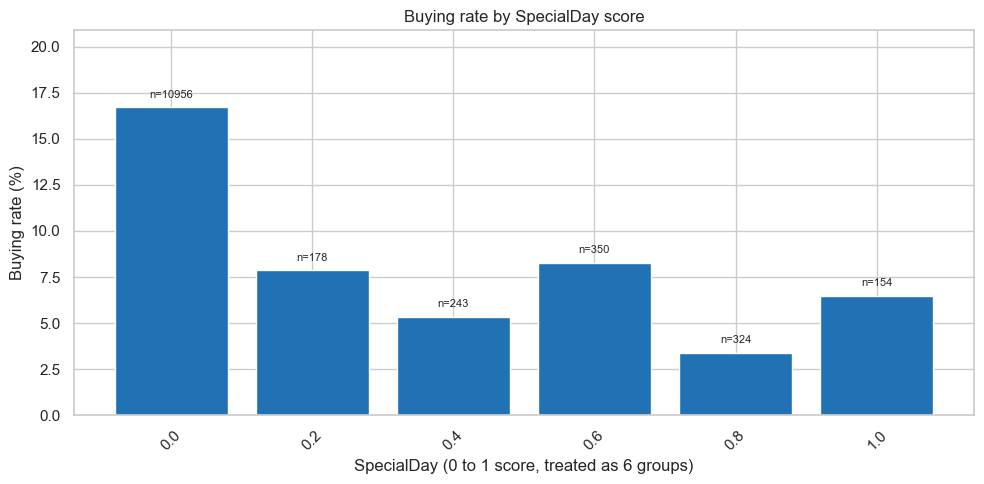

,buyers,n,rate
SpecialDay,,,
0.0,1831,10956,16.712304
0.2,14,178,7.865169
0.4,13,243,5.349794
0.6,29,350,8.285714
0.8,11,324,3.395062
1.0,10,154,6.493506


In [9]:
buying_rate_bars(
    df,
    "SpecialDay",
    "buying_rate_special_day",
    "Buying rate by SpecialDay score",
    "SpecialDay (0 to 1 score, treated as 6 groups)",
    order=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
)


A `SpecialDay` score of 0 buys at **16.71%** (n = **10,956**). Every score above 0 buys less. The lowest is 0.8, at **3.40%** (n = **324**). All six scores have at least 100 rows.


TrafficType
             buyers     n   rate
TrafficType                     
1               262  2388  10.97
2               847  3911  21.66
3               180  2013   8.94
4               165  1066  15.48
5                56   260  21.54
6                53   443  11.96
7                12    40  30.00
8                95   343  27.70
9                 4    41   9.76
10               90   450  20.00
11               47   247  19.03
12                0     1   0.00
13               43   728   5.91
14                2    13  15.38
15                0    37   0.00
16                1     3  33.33
17                0     1   0.00
18                0    10   0.00
19                1    17   5.88
20               50   193  25.91
Groups under 100 rows: ['7', '9', '12', '14', '15', '16', '17', '18', '19']


Saved: ../images/02_buying_rate_traffic_type.png


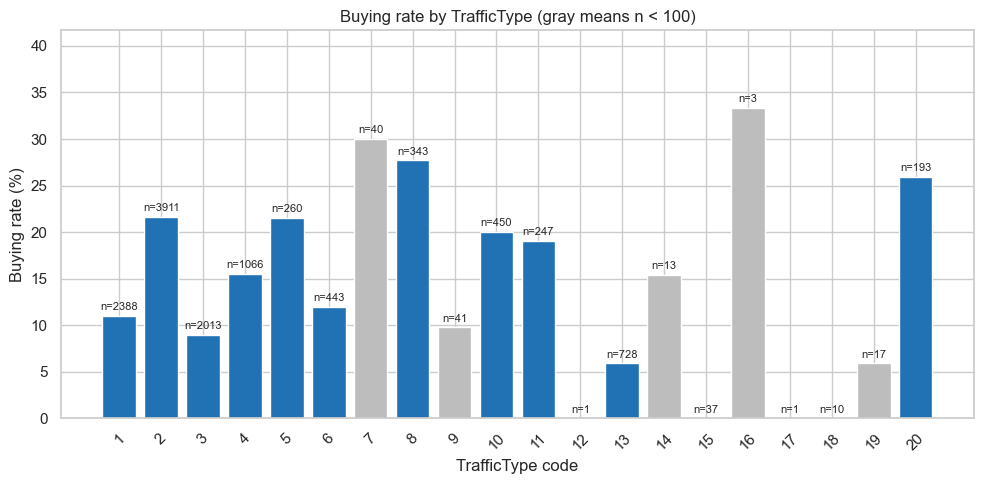

,buyers,n,rate
TrafficType,,,
1,262,2388,10.971524
2,847,3911,21.656865
3,180,2013,8.941878
4,165,1066,15.478424
5,56,260,21.538462
6,53,443,11.963883
7,12,40,30.000000
8,95,343,27.696793
9,4,41,9.756098


In [10]:
traffic_order = sorted(df["TrafficType"].unique(), key=lambda value: int(value))
buying_rate_bars(
    df,
    "TrafficType",
    "buying_rate_traffic_type",
    "Buying rate by TrafficType (gray means n < 100)",
    "TrafficType code",
    order=traffic_order,
)


Among codes with at least 100 rows, code **8** buys at **27.70%** (n = **343**) and code **13** buys at **5.91%** (n = **728**). Code **2** is the largest source, at **21.66%** (n = **3,911**). Codes 7, 9, 12, 14, 15, 16, 17, 18, and 19 have fewer than 100 rows, so those percents are unreliable.


Region
        buyers     n   rate
Region                     
1          771  4714  16.36
2          188  1128  16.67
3          349  2379  14.67
4          175  1171  14.94
5           52   318  16.35
6          112   801  13.98
7          119   758  15.70
8           56   431  12.99
9           86   505  17.03
Groups under 100 rows: []


Saved: ../images/02_buying_rate_region.png


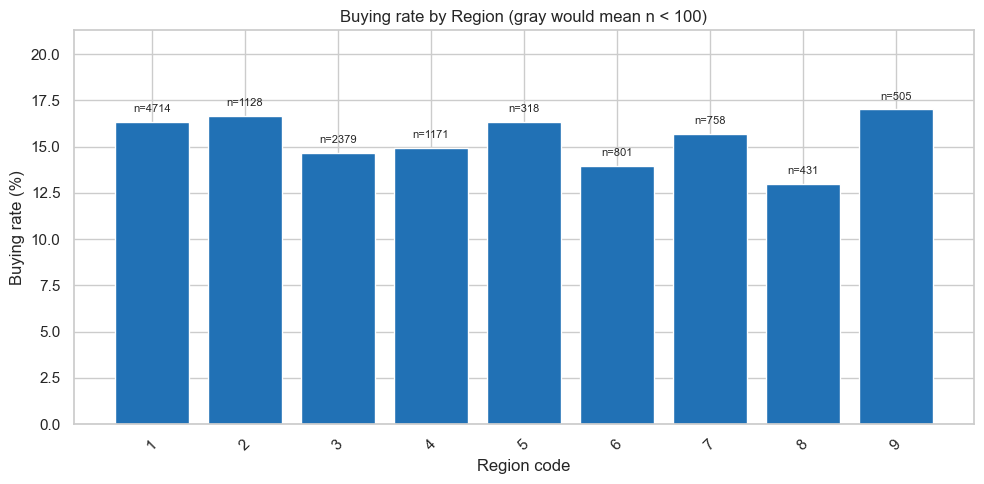

,buyers,n,rate
Region,,,
1,771,4714,16.355537
2,188,1128,16.666667
3,349,2379,14.670029
4,175,1171,14.944492
5,52,318,16.352201
6,112,801,13.982522
7,119,758,15.699208
8,56,431,12.993039
9,86,505,17.029703


In [11]:
region_order = sorted(df["Region"].unique(), key=lambda value: int(value))
buying_rate_bars(
    df,
    "Region",
    "buying_rate_region",
    "Buying rate by Region (gray would mean n < 100)",
    "Region code",
    order=region_order,
)


Region buying rates only run from **12.99%** in region 8 (n = **431**) to **17.03%** in region 9 (n = **505**). Every region has at least 100 rows.
